In [3]:
import torch
import torchvision
from torch.utils.data import random_split
from torchvision import datasets, transforms
from torchvision.transforms import ToTensor

from torch.nn import (Module, Conv2d, Linear, MaxPool2d,Sequential, Sigmoid,
                      ReLU, LogSoftmax)

from torch import flatten 

import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from copy import deepcopy
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score
from typing import Dict, Any, Optional, List, Tuple

# Задание 1. 
По своему номеру варианта и таблице 1 определить номер набора данных и
требования к архитектуре сети:

Номер варианта 6 

Номер набора данных 2 

Номер архитектуры сети 2

# Задание 2. 
По номеру набора входных данных выяснить из таблицы 2 его название. Так
как многие наборы данных имеются в библиотеках в готовом для обработки виде, желательно
сразу же проверить его наличие в используемой библиотеке. Списки готовых датасетов для
некоторых библиотек доступны по ссылкам:

CIFAR10: https://www.cs.toronto.edu/~kriz/cifar.html

In [2]:
train_data = torchvision.datasets.CIFAR10(root = 'dataset/', train = True, transform = ToTensor(), download = True)
test_data = torchvision.datasets.CIFAR10(root = 'dataset/', train = False, transform = ToTensor(), download = True)

100%|██████████| 170M/170M [18:11<00:00, 156kB/s]  


Extracting dataset/cifar-10-python.tar.gz to dataset/
Files already downloaded and verified


# Задание 3. 
Определить требования к архитектуре сети из таблицы 3, после чего собрать
сеть, удовлятворяющую этим требованиям и способную обработать указанные данные. Можно
использовать как примеры следующие материалы:

Число слоёв кодировщика и декодировщика — 3, 

минимальное число признаков — 20

In [11]:
class MyAutoencoder(Module):
    def __init__(self, layer3_num = 32):
        Module.__init__(self)
        input_dim = 3 * 32 * 32
        layer1_num = 128
        layer2_num = 64
        layer3_num = 32
        # создаём сеть-кодировщик.
        self.encoder = Sequential(
            nn.Flatten(),    # превращаем [batch, 3, 32, 32] в [batch, 3072]
            Linear(input_dim, layer1_num),
            ReLU(),
            Linear(layer1_num, layer2_num),
            ReLU(),
            Linear(layer2_num, layer3_num))
        
        # создаём сеть-декодировщик с аналогичными слоями,
        # расположенными в обратном порядке. Последний
        # слой позволяет ограничить диапазон выходов
        self.decoder = Sequential(
            Linear(layer3_num, layer2_num),
            ReLU(),
            Linear(layer2_num, layer1_num),
            ReLU(),
            Linear(layer1_num, input_dim),
            Sigmoid(),
            nn.Unflatten(1, (3, 32, 32))) # возвращаем форму [batch, 3, 32, 32])
        
    def forward(self, x):
        # при работе сети пропускаем данные
        # через обе части последовательно
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

# Задание 4. 
Обучить сеть на указанных данных, оценить точность восстановления любым
применимым критерием, например MSE.

In [6]:
class EarlyStopping():
  def __init__(
        self, 
        mode = 'min', 
        patience = 5, 
        threshold= 1e-4, 
        threshold_mode = 'rel'
    ):
    if mode not in {'min','max'}:
      raise ValueError(f"Available values for mode: max, min")
    if threshold_mode not in {'rel','abs'}:
      raise ValueError(f"Available values for threshold_mode: rel, abs")
    if not isinstance(patience, int):
      raise ValueError(f"Available values for patience must be int")
    if not isinstance(threshold, float):
      raise ValueError(f"Available values for threshold must be int and less than 1,0.")
    if threshold >= 1.0:
      raise ValueError(f"Available values for threshold must be int and less than 1,0.")

    self.mode = mode
    self.patience = patience
    self.threshold = threshold
    self.threshold_mode = threshold_mode
    self.count = 0
    self.best = None

  def changed_better(self, current, best):
    if self.mode == 'min' and self.threshold_mode == 'rel':
      return current < best - best * self.threshold
    elif self.mode == 'min' and self.threshold_mode == 'abs':
      return current < best - self.threshold

    elif self.mode =='max' and self.threshold_mode == 'rel':
      return current > best + best * self.threshold
    else:
      return current > best + self.threshold

  def __call__(self, tracked_parameter):
    current = float(tracked_parameter)
    if self.best is None:
      self.best = current
      return False

    if self.changed_better(current, self.best):
      self.best = current
      self.count = 0
    else:
      self.count += 1

    if self.count >= self.patience:
      self.count = 0
      return True

In [7]:
def train_autoencoder(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    lr: float = 1e-3,
    optimizer_name: str = 'Adam',
    scheduler_name: Optional[str] = 'ReduceLROnPlateau',
    weight_decay: float = 0.0,
    n_epochs: int = 50,
    early_stopping_patience: int = 5,
    loss_name: str = 'MSELoss',
    device: str = 'cuda',
    verbose: bool = True
) -> Dict[str, Any]:
    
    device = device if torch.cuda.is_available() else 'cpu'
    model.to(device)

    loss_model = getattr(nn, loss_name)()
    optimizer_cls = getattr(optim, optimizer_name)
    opt = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay)

    lr_scheduler = None
    if scheduler_name in ('Plateau', 'ReduceLROnPlateau'):
        lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            opt, mode='min', factor=0.1, patience=3
        )
    elif scheduler_name in ('Cosine', 'CosineAnnealingLR'):
        lr_scheduler = optim.lr_scheduler.CosineAnnealingLR(
            opt, T_max=n_epochs, eta_min=0.0
        )
    elif scheduler_name is not None:
        raise ValueError(f"Scheduler name: {scheduler_name} not in script")

    earlystopping = EarlyStopping(patience=early_stopping_patience)

    history = {
        'train_loss': [],
        'val_loss': [],
        'lr': []
    }
    best_val_loss = float('inf')
    best_model_weights = deepcopy(model.state_dict())
    
    for epoch in range(n_epochs):
        # TRAINING 
        model.train()
        running_train_loss = []

        train_loop = tqdm(train_loader, leave=False, disable=not verbose)
        for x, _ in train_loop:  # Метки классов игнорируем
            x = x.to(device)

            # Forward
            pred = model(x)
            loss = loss_model(pred, x)  # Сравниваем выход с входом x

            # Backward
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

            running_train_loss.append(loss.item())
            mean_train_loss = np.mean(running_train_loss)

            if verbose:
                train_loop.set_description(f"Epoch [{epoch+1}/{n_epochs}], train_loss = {mean_train_loss:.4f}")

        history['train_loss'].append(mean_train_loss)

        # VALIDATION 
        model.eval()
        running_val_loss = []

        with torch.no_grad():
            for x, _ in val_loader:
                x = x.to(device)
                pred = model(x)
                loss = loss_model(pred, x)
                running_val_loss.append(loss.item())

        mean_val_loss = np.mean(running_val_loss)
        history['val_loss'].append(mean_val_loss)

        # Scheduler step 
        if lr_scheduler is not None:
            if scheduler_name in ('Plateau', 'ReduceLROnPlateau'):
                lr_scheduler.step(mean_val_loss)
            else:
                lr_scheduler.step()

        current_lr = opt.param_groups[0]['lr']
        history['lr'].append(current_lr)

        if verbose:
            print(
                f"Epoch [{epoch+1}/{n_epochs}] | "
                f"train_loss: {mean_train_loss:.4f} | "
                f"val_loss: {mean_val_loss:.4f} | lr: {current_lr:.6f}"
            )

        # Saving best
        if mean_val_loss < best_val_loss:
            best_val_loss = mean_val_loss
            best_model_weights = deepcopy(model.state_dict())

        # Checking EarlyStopping
        if earlystopping(mean_val_loss):
            if verbose:
                print(f"Early stopping worked on {epoch+1}")
            break

    model.load_state_dict(best_model_weights)

    return {
        'model': model,
        'best_val_loss': best_val_loss,
        'epochs_trained': epoch + 1,
        'history': history
    }

In [8]:
def visualize_reconstructions(model, test_loader, device='cuda', n_images=8):
    device = device if torch.cuda.is_available() else 'cpu'
    model.to(device)
    model.eval()

    # Берем один батч из тестовой выборки
    images, _ = next(iter(test_loader))
    images = images[:n_images].to(device)

    # Получаем восстановленные картинки без расчета градиентов
    with torch.no_grad():
        reconstructed = model(images)

    # Переносим на CPU, переводим в numpy и меняем порядок осей: (N, C, H, W) -> (N, H, W, C)
    images = images.cpu().permute(0, 2, 3, 1).numpy()
    reconstructed = reconstructed.cpu().permute(0, 2, 3, 1).numpy()

    # Строим сетку 2 x n_images
    fig, axes = plt.subplots(2, n_images, figsize=(n_images * 2, 4.5))
    
    for i in range(n_images):
        # Верхний ряд: исходные изображения
        axes[0, i].imshow(images[i])
        axes[0, i].axis('off')
        if i == 0:
            axes[0, i].set_title("Исходные (CIFAR-10)", loc='left', fontsize=12)

        # Нижний ряд: восстановленные изображения
        axes[1, i].imshow(reconstructed[i])
        axes[1, i].axis('off')
        if i == 0:
            axes[1, i].set_title("Восстановленные", loc='left', fontsize=12)

    plt.tight_layout()
    plt.show()

In [9]:
generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(train_data,batch_size = 32,
                             shuffle = True, generator = generator)

test_loader = DataLoader(test_data, batch_size=32, generator = generator)

In [12]:
model = MyAutoencoder()
results = train_autoencoder(
    model=model,
    train_loader=train_loader,
    val_loader=test_loader
)

Epoch [1/50] | train_loss: 0.0289 | val_loss: 0.0230 | lr: 0.001000


Epoch [2/50] | train_loss: 0.0221 | val_loss: 0.0207 | lr: 0.001000


Epoch [3/50] | train_loss: 0.0201 | val_loss: 0.0195 | lr: 0.001000


Epoch [4/50] | train_loss: 0.0186 | val_loss: 0.0179 | lr: 0.001000


Epoch [5/50] | train_loss: 0.0176 | val_loss: 0.0173 | lr: 0.001000


Epoch [6/50] | train_loss: 0.0169 | val_loss: 0.0169 | lr: 0.001000


... (40 outputs left out)

Epoch [47/50] | train_loss: 0.0134 | val_loss: 0.0134 | lr: 0.000010


Epoch [48/50] | train_loss: 0.0134 | val_loss: 0.0134 | lr: 0.000010


Epoch [49/50] | train_loss: 0.0134 | val_loss: 0.0134 | lr: 0.000010


Epoch [50/50] | train_loss: 0.0134 | val_loss: 0.0134 | lr: 0.000010


In [13]:
print(f"Минимальная ошибка на тестовой выборке(MSE): {results['best_val_loss']:.4f}")
print(f"Количество эпох: {results['epochs_trained'] }")

Минимальная ошибка на тестовой выборке(MSE): 0.0134
Количество эпох: 50


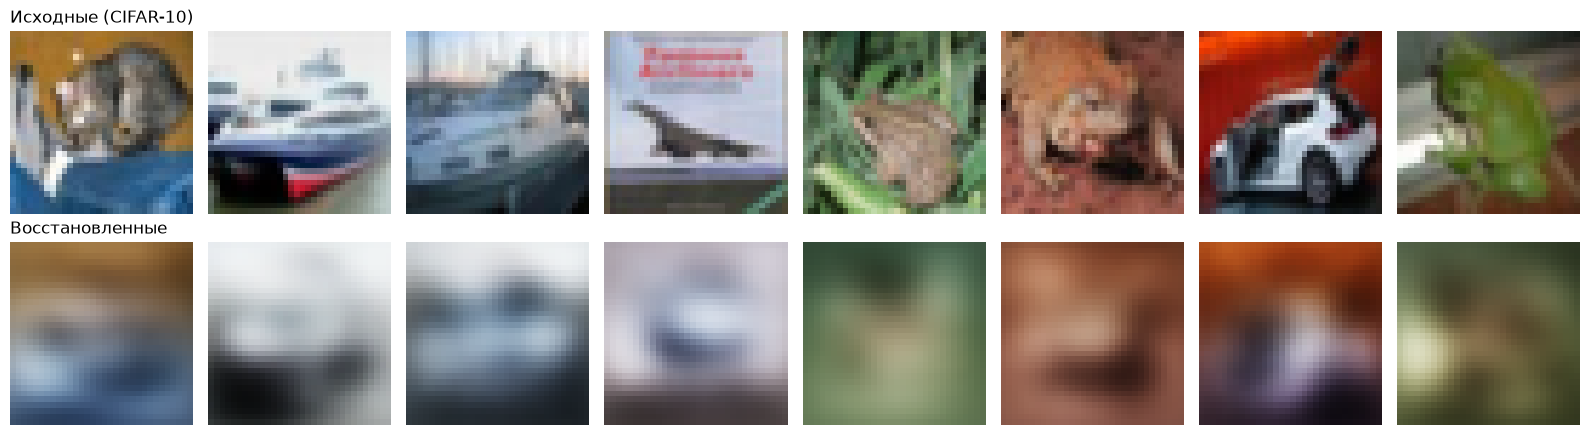

In [14]:
visualize_reconstructions(model, test_loader, device='cuda', n_images=8)

Признаков слишком мало, те происходит сильное сжатие. Часть важной информации об изображении теряется, из-за чего ошибка растет, а картинка становится размытой

In [15]:
records = [
    {
        'num_features': 32,
        'MSE': results['best_val_loss'],
        'epochs': results['epochs_trained']
    }
]

# Задание 5. 
Увеличить количество признаков в два, а затем в четыре раза. Оценить зави-
симость точности обученной модели от количества признаков.

Epoch [1/50] | train_loss: 0.0279 | val_loss: 0.0226 | lr: 0.001000


Epoch [2/50] | train_loss: 0.0210 | val_loss: 0.0199 | lr: 0.001000


Epoch [3/50] | train_loss: 0.0190 | val_loss: 0.0183 | lr: 0.001000


Epoch [4/50] | train_loss: 0.0179 | val_loss: 0.0176 | lr: 0.001000


Epoch [5/50] | train_loss: 0.0170 | val_loss: 0.0167 | lr: 0.001000


Epoch [6/50] | train_loss: 0.0162 | val_loss: 0.0161 | lr: 0.001000


... (40 outputs left out)

Epoch [47/50] | train_loss: 0.0125 | val_loss: 0.0126 | lr: 0.001000


Epoch [48/50] | train_loss: 0.0125 | val_loss: 0.0126 | lr: 0.000100


Epoch [49/50] | train_loss: 0.0122 | val_loss: 0.0123 | lr: 0.000100


Epoch [50/50] | train_loss: 0.0122 | val_loss: 0.0123 | lr: 0.000100
Минимальная ошибка на тестовой выборке(MSE): 0.0123
Количество эпох: 50


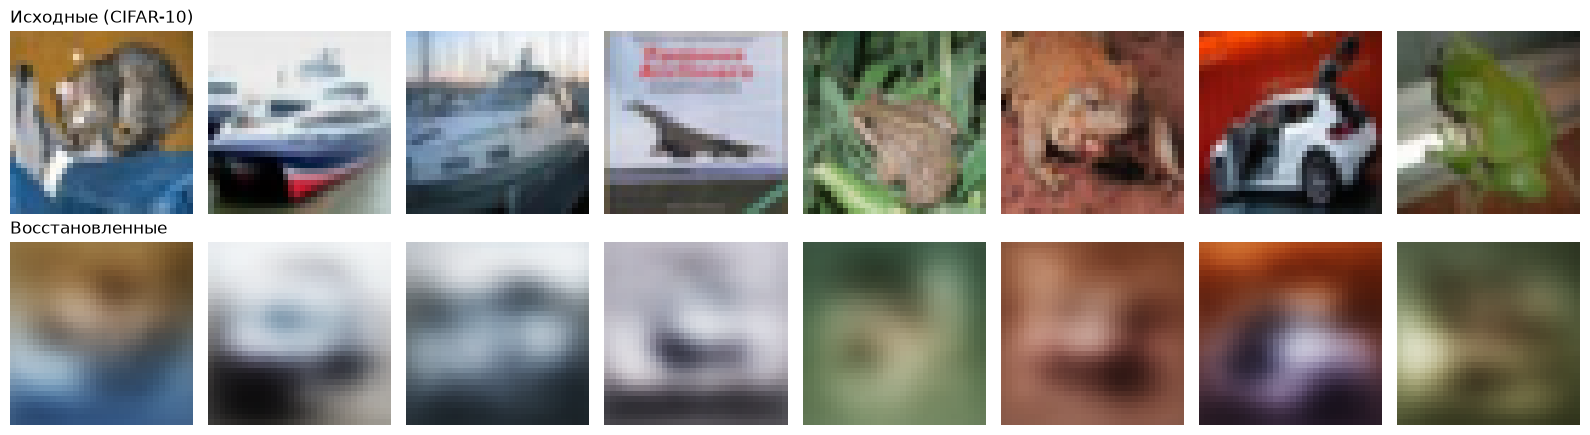

Epoch [1/50] | train_loss: 0.0286 | val_loss: 0.0230 | lr: 0.001000


Epoch [2/50] | train_loss: 0.0212 | val_loss: 0.0200 | lr: 0.001000


Epoch [3/50] | train_loss: 0.0188 | val_loss: 0.0179 | lr: 0.001000


Epoch [4/50] | train_loss: 0.0173 | val_loss: 0.0171 | lr: 0.001000


Epoch [5/50] | train_loss: 0.0169 | val_loss: 0.0168 | lr: 0.001000


Epoch [6/50] | train_loss: 0.0163 | val_loss: 0.0163 | lr: 0.001000


... (40 outputs left out)

Epoch [47/50] | train_loss: 0.0125 | val_loss: 0.0126 | lr: 0.001000


Epoch [48/50] | train_loss: 0.0125 | val_loss: 0.0126 | lr: 0.001000


Epoch [49/50] | train_loss: 0.0125 | val_loss: 0.0125 | lr: 0.001000


Epoch [50/50] | train_loss: 0.0125 | val_loss: 0.0126 | lr: 0.001000
Минимальная ошибка на тестовой выборке(MSE): 0.0125
Количество эпох: 50


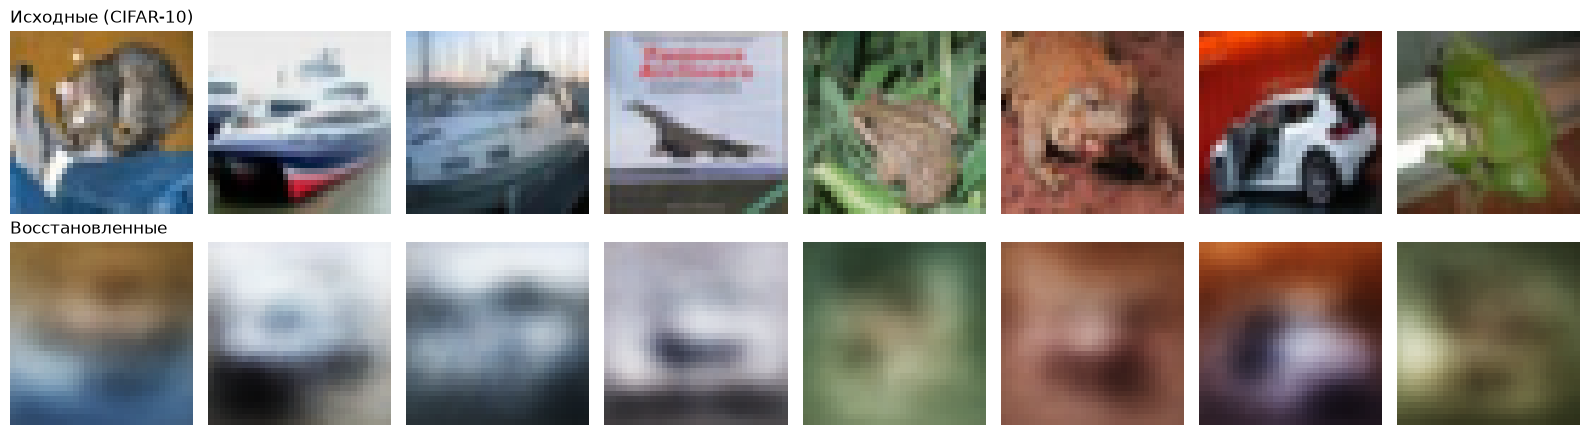

In [16]:
layer_nums = [64, 256]
for layer_num in layer_nums:
    model = MyAutoencoder(layer3_num = layer_num)
    results = train_autoencoder(
        model=model,
        train_loader=train_loader,
        val_loader=test_loader
    )

    records.append({
        'num_features': layer_num,
        'MSE': results['best_val_loss'],
        'epochs': results['epochs_trained']
    })

    print(f"Минимальная ошибка на тестовой выборке(MSE): {results['best_val_loss']:.4f}")
    print(f"Количество эпох: {results['epochs_trained'] }")

    visualize_reconstructions(model, test_loader, device='cuda', n_images=8)

In [17]:
df = pd.DataFrame(records)
df

,num_features,MSE,epochs
0,32,0.013443,50
1,64,0.012266,50
2,256,0.012515,50


# Задание 7. 
Для какой-либо из обученных моделей попытаться сгенерировать новые изображения, интерполирующие старые: выбрать два базовых изображения, рассчитать их векторы признаков v1 и v2, вычислить несколько их линейных комбинаций w = αv1 + (1−α)v2, α ∈ (0, 1);

сгенерировать изображения по этим векторам, сравнить их с исходными.

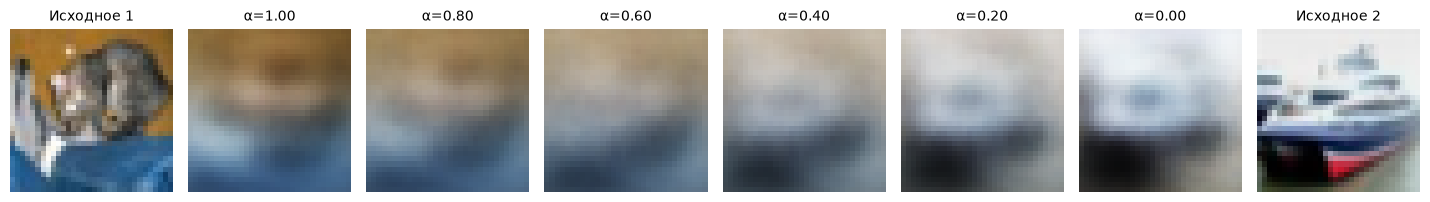

In [18]:
def interpolate_images(model, test_loader, idx1=0, idx2=1, steps=8, device='cuda'):
    device = device if torch.cuda.is_available() else 'cpu'
    model.to(device)
    model.eval()

    # Берём батч картинок из тестового набора
    images, _ = next(iter(test_loader))
    img1 = images[idx1].unsqueeze(0).to(device)  # форма [1, 3, 32, 32]
    img2 = images[idx2].unsqueeze(0).to(device)  # форма [1, 3, 32, 32]

    # Коэффициенты alpha от 1.0 (чистый img1) до 0.0 (чистый img2)
    alphas = np.linspace(1.0, 0.0, steps)

    with torch.no_grad():
        # 1. Получаем векторы признаков v1 и v2 через кодировщик
        v1 = model.encoder(img1)
        v2 = model.encoder(img2)

        # 2. Вычисляем линейные комбинации w = alpha * v1 + (1 - alpha) * v2
        # и декодируем их обратно в изображения
        interpolated_imgs = []
        for alpha in alphas:
            w = alpha * v1 + (1.0 - alpha) * v2
            generated = model.decoder(w)
            interpolated_imgs.append(generated.squeeze(0).cpu().permute(1, 2, 0).numpy())

    # 3. Отрисовка результата
    # Первая и последняя ячейки — реальные исходные картинки, между ними — переходы
    fig, axes = plt.subplots(1, steps + 2, figsize=((steps + 2) * 1.8, 2.5))

    # Исходное изображение 1
    axes[0].imshow(img1.squeeze(0).cpu().permute(1, 2, 0).numpy())
    axes[0].set_title("Исходное 1", fontsize=10)
    axes[0].axis('off')

    # Промежуточные генерации (включая alpha=1 и alpha=0 как реконструкции)
    for i, (img, alpha) in enumerate(zip(interpolated_imgs, alphas)):
        axes[i + 1].imshow(img)
        axes[i + 1].set_title(f"α={alpha:.2f}", fontsize=10)
        axes[i + 1].axis('off')

    # Исходное изображение 2
    axes[-1].imshow(img2.squeeze(0).cpu().permute(1, 2, 0).numpy())
    axes[-1].set_title("Исходное 2", fontsize=10)
    axes[-1].axis('off')

    plt.tight_layout()
    plt.show()

# Запуск функции
interpolate_images(model, test_loader, idx1=0, idx2=1, steps=6)

# Контрольные вопросы

1. Как влияет на качество результатов восстановления число признаков?

Если признаков слишком мало, то происходит сильное сжатие. Часть важной информации об изображении теряется, из-за чего ошибка растет, а картинка становится размытой.

Если признаков много, сеть способна сохранить больше деталей и качество растет. Однако при большом числе признаков, близкому к размеру исходного изорбражения, автоэнкодер теряет смысл. Он просто копирует входные пиксели, теряя обобщающую способность

2. Как влияет на качество результатов восстановления и обучение сети число скрытых слоёв
в кодировщике и декодировщике?

Число скрытых слоев влияет на сложность и абстрактность признаков, которые способна извлечь сеть. Это позволяет лучше сжимать и точнее восстанавливать сложные изображения.

Также увеличение слоев логичным образом замедляет обучение. Растет число параметров и повышается риск переобучения. А при слишком большой глубине есть риск затухания градиентов.

# Размытость

Сейчас изображения на выходе очень размыты. Заменим архитектуру на сверточную и в качестве метрики возьмем L1

In [19]:
class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        
        # Кодировщик: 3 свёрточных слоя + переход в вектор признаков latent_dim
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, stride=2, padding=1),   # -> [16, 16, 16]
            nn.BatchNorm2d(16),
            nn.LeakyReLU(0.2),
            
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),  # -> [32, 8, 8]
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2),
            
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),  # -> [64, 4, 4]
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            
            nn.Flatten(),                                           # -> [1024]
            nn.Linear(64 * 4 * 4, latent_dim)                       # -> [latent_dim]
        )
        
        # Декодировщик: разворачивает вектор latent_dim обратно + 3 слоя ConvTranspose2d
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 4 * 4),                      # -> [1024]
            nn.LeakyReLU(0.2),
            nn.Unflatten(1, (64, 4, 4)),                            # -> [64, 4, 4]
            
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1), # -> [32, 8, 8]
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2),
            
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1), # -> [16, 16, 16]
            nn.BatchNorm2d(16),
            nn.LeakyReLU(0.2),
            
            nn.ConvTranspose2d(16, 3, kernel_size=3, stride=2, padding=1, output_padding=1),  # -> [3, 32, 32]
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [20]:
model = ConvAutoencoder()
results = train_autoencoder(
    model=model,
    train_loader=train_loader,
    val_loader=test_loader
)

Epoch [1/50] | train_loss: 0.0135 | val_loss: 0.0092 | lr: 0.001000


Epoch [2/50] | train_loss: 0.0095 | val_loss: 0.0090 | lr: 0.001000


Epoch [3/50] | train_loss: 0.0091 | val_loss: 0.0084 | lr: 0.001000


Epoch [4/50] | train_loss: 0.0089 | val_loss: 0.0083 | lr: 0.001000


Epoch [5/50] | train_loss: 0.0088 | val_loss: 0.0082 | lr: 0.001000


Epoch [6/50] | train_loss: 0.0087 | val_loss: 0.0082 | lr: 0.001000


... (33 outputs left out)

Epoch [40/50] | train_loss: 0.0079 | val_loss: 0.0077 | lr: 0.000010


Epoch [41/50] | train_loss: 0.0079 | val_loss: 0.0078 | lr: 0.000010


Epoch [42/50] | train_loss: 0.0079 | val_loss: 0.0078 | lr: 0.000001


Epoch [43/50] | train_loss: 0.0079 | val_loss: 0.0078 | lr: 0.000001
Early stopping worked on 43


In [21]:
print(f"Минимальная ошибка на тестовой выборке(L1): {results['best_val_loss']:.4f}")
print(f"Количество эпох: {results['epochs_trained'] }")

Минимальная ошибка на тестовой выборке(L1): 0.0077
Количество эпох: 43


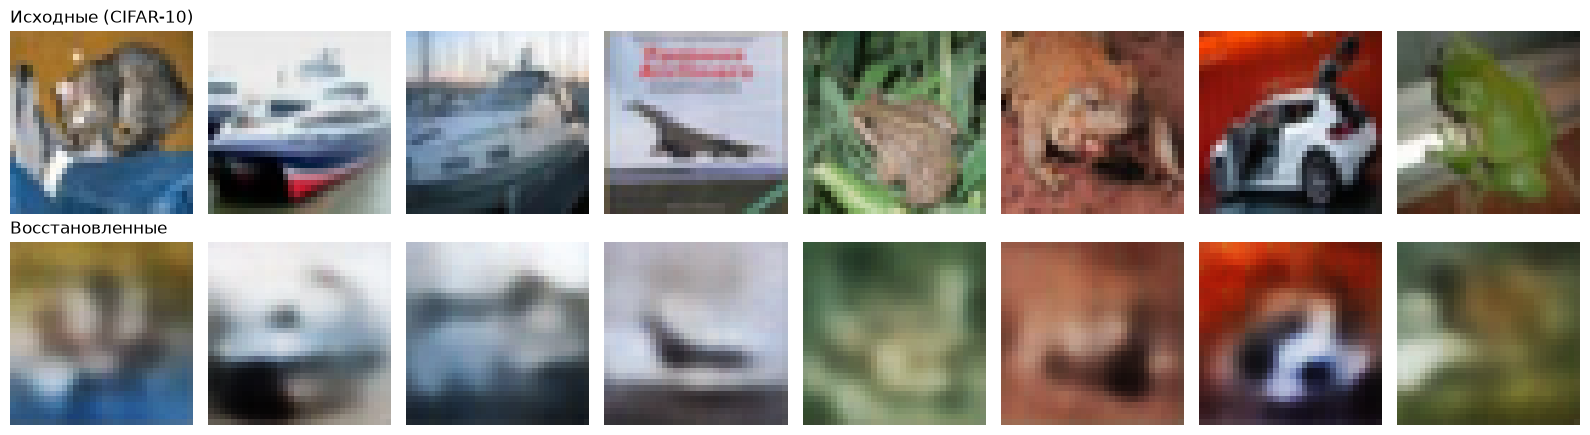

In [22]:
visualize_reconstructions(model, test_loader, device='cuda', n_images=8)

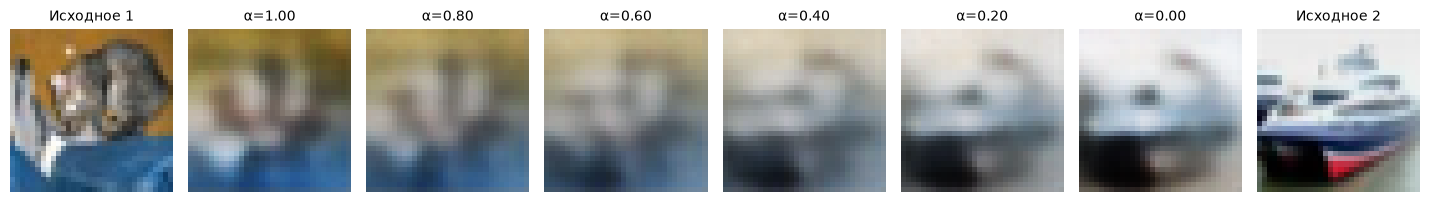

In [23]:
interpolate_images(model, test_loader, idx1=0, idx2=1, steps=6)